## Задание по библиотекам Pandas и Matplotlib
### Лабораторная работа № 3 по дисциплине "Технологии программирования"

Подключаем необходимые библиотеки:

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Скачиваем датасет с информацией о пассажирах Титаника:

In [17]:
!wget https://web.stanford.edu/class/archive/cs/cs109/cs109.1166/stuff/titanic.csv

"wget" �� ���� ����७��� ��� ���譥�
��������, �ᯮ��塞�� �ணࠬ��� ��� ������ 䠩���.


Проверяем наличие скачанного датасета:



In [18]:
!ls

"ls" �� ���� ����७��� ��� ���譥�
��������, �ᯮ��塞�� �ணࠬ��� ��� ������ 䠩���.


Значения колонок датасета следующие (__в соответствии с информацией с сайта__):
*    Survived Indicator (выжил пассажир или нет)
*    Passenger Class (класс)
*    Name (имя)
*    Sex (пол)
*    Age (возраст)
*    Siblings/Spouses Aboard (есть ли братья, сестры или супруг(а) на борту)
*    Parents/Children Aboard (есть ли родители или дети на борту)
*    Fare paid in £s (цена билета в фунтах стерлингов)

Загружаем данные и формируем Pandas DataFrame:

In [19]:
df = pd.read_csv('titanic.csv')
df

,Survived,Pclass,Name,Sex,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare
0,0,3,Mr. Owen Harris Braund,male,22.0,1,0,7.2500
1,1,1,Mrs. John Bradley (Florence Briggs Thayer) Cum...,female,38.0,1,0,71.2833
2,1,3,Miss. Laina Heikkinen,female,26.0,0,0,7.9250
3,1,1,Mrs. Jacques Heath (Lily May Peel) Futrelle,female,35.0,1,0,53.1000
4,0,3,Mr. William Henry Allen,male,35.0,0,0,8.0500
...,...,...,...,...,...,...,...,...
882,0,2,Rev. Juozas Montvila,male,27.0,0,0,13.0000
883,1,1,Miss. Margaret Edith Graham,female,19.0,0,0,30.0000
884,0,3,Miss. Catherine Helen Johnston,female,7.0,1,2,23.4500
885,1,1,Mr. Karl Howell Behr,male,26.0,0,0,30.0000


__С использованием датафрейма нужно выполнить следующие задания__.

1. Определите, содержит ли какой-нибудь столбец датасета пропущенные значения.

In [20]:
missing = df.isna().sum()
print(missing)
print()
if missing.sum() == 0:
    print('Ни один столбец не содержит пропущенных значений.')
else:
    print('Пропущенные значения есть в столбцах:')
    print(missing[missing > 0])

Survived                   0
Pclass                     0
Name                       0
Sex                        0
Age                        0
Siblings/Spouses Aboard    0
Parents/Children Aboard    0
Fare                       0
dtype: int64

Ни один столбец не содержит пропущенных значений.


2. В соответствии с вариантом, определите:

   1. Количество женщин старше 50 лет на борту.
   2. Количество пассажиров, путешествующих вторым классом вместе с родителями или детьми.
   3. Число погибших детей в возрасте до 12 лет, путешествующих первым классом.
   4. Среднее значение коэффициента выживаемости десяти пассажиров третьего класса с самыми дорогими билетами.
   5. Среднее значение цены билета пассажиров, путешествующих без родственников.

In [21]:
# Вариант 2: пассажиры второго класса, которые едут вместе с родителями или детьми
second_class_with_family = df[(df['Pclass'] == 2) & (df['Parents/Children Aboard'] > 0)]
print(f'Количество пассажиров: {len(second_class_with_family)}')
second_class_with_family

Количество пассажиров: 50


,Survived,Pclass,Name,Sex,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare
42,1,2,Miss. Simonne Marie Anne Andree Laroche,female,3.00,1,2,41.5792
57,1,2,Miss. Constance Mirium West,female,5.00,1,2,27.7500
77,1,2,Master. Alden Gates Caldwell,male,0.83,0,2,29.0000
97,1,2,Mrs. John T (Ada Julia Bone) Doling,female,34.00,0,1,23.0000
144,0,2,Mr. Joseph Charles Nicholls,male,19.00,1,1,36.7500
147,0,2,Mr. Michel Navratil,male,36.50,0,2,26.0000
182,1,2,Master. Richard F Becker,male,1.00,2,1,39.0000
192,1,2,Master. Michel M Navratil,male,3.00,1,1,26.0000
236,1,2,Miss. Marjorie Collyer,female,8.00,0,2,26.2500
246,1,2,Mrs. William (Anna) Hamalainen,female,24.00,0,2,14.5000


3. Постройте диаграмму распределения значений цены билета по всем пассажирам. Проинтерпретируйте результат. Можно ли сказать, что в данных наблюдаются выбросы?

C:\Users\artme\AppData\Local\Temp\ipykernel_13396\3810861974.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(df['Fare'], vert=True)


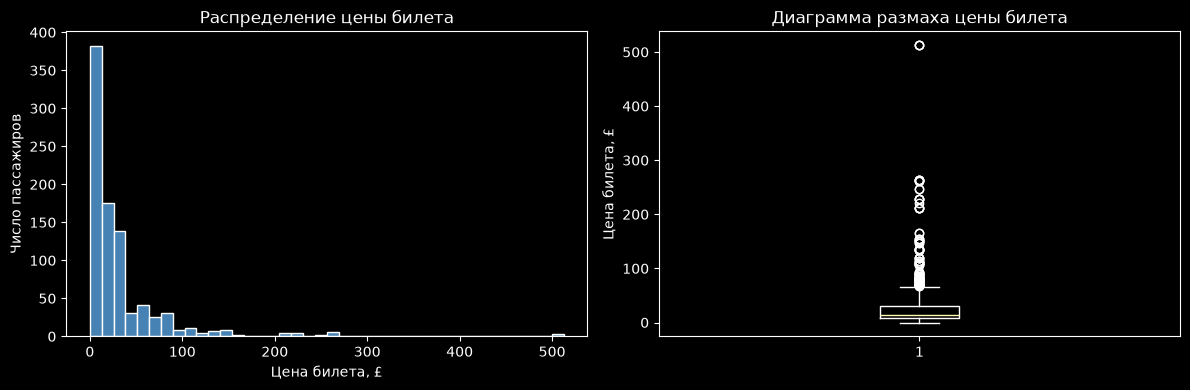

Медиана: 14.45 £
Среднее: 32.31 £
Максимум: 512.33 £
Верхняя граница выбросов (Q3 + 1.5·IQR): 65.96 £
Число выбросов: 116 из 887


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df['Fare'], bins=40, color='steelblue', edgecolor='white')
axes[0].set_title('Распределение цены билета')
axes[0].set_xlabel('Цена билета, £')
axes[0].set_ylabel('Число пассажиров')

axes[1].boxplot(df['Fare'], vert=True)
axes[1].set_title('Диаграмма размаха цены билета')
axes[1].set_ylabel('Цена билета, £')

plt.tight_layout()
plt.show()

q1 = df['Fare'].quantile(0.25)
q3 = df['Fare'].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
outliers = df[(df['Fare'] < lower) | (df['Fare'] > upper)]

print(f'Медиана: {df["Fare"].median():.2f} £')
print(f'Среднее: {df["Fare"].mean():.2f} £')
print(f'Максимум: {df["Fare"].max():.2f} £')
print(f'Верхняя граница выбросов (Q3 + 1.5·IQR): {upper:.2f} £')
print(f'Число выбросов: {len(outliers)} из {len(df)}')

Распределение цены билета сильно скошено вправо. Большинство пассажиров купили дешёвые билеты: медиана около 14 £, тогда как среднее заметно выше — около 32 £. Справа тянется длинный хвост дорогих билетов, максимум — 512 £.

Выбросы есть. По правилу ящика с усами (1.5 · IQR) за верхнюю границу выходит более ста билетов. На диаграмме размаха это видно как точки далеко над основной массой наблюдений.

4. В соответствии с вариантом, определите, верны ли следующие утверждения. Приведите доказательства ответа.

  1. Чем дороже билет, тем выше вероятность выжить.
  2. Мужчинам в катастрофе выжить проще.
  3. Чем больше родственников у человека, тем выше шанс того, что он купит билет третьего класса.
  4. Если Вам больше 70 лет, то шансов выжить в катастрофе у Вас практически нет.
  5. Чем больше родственников у чаловека, тем выше его шанс погибнуть.

        выжило  всего      доля
Sex                            
female     233    314  0.742038
male       109    573  0.190227

Доля выживших женщин: 74.2%
Доля выживших мужчин: 19.0%
Утверждение ложно: доля выживших среди женщин примерно в 4 раза выше, чем среди мужчин.


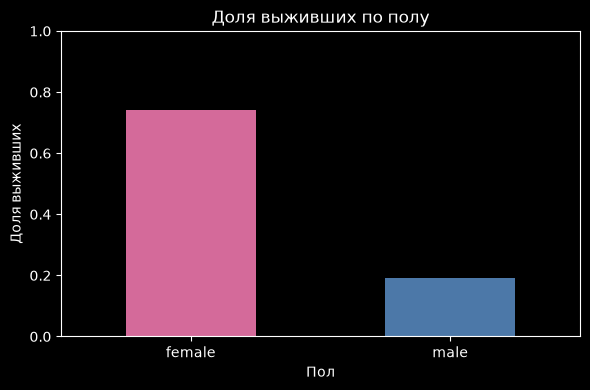

In [23]:
# Вариант 2: «Мужчинам в катастрофе выжить проще»
survival_by_sex = df.groupby('Sex')['Survived'].agg(выжило='sum', всего='count', доля='mean')
print(survival_by_sex)
print()

female_rate = survival_by_sex.loc['female', 'доля']
male_rate = survival_by_sex.loc['male', 'доля']
print(f'Доля выживших женщин: {female_rate:.1%}')
print(f'Доля выживших мужчин: {male_rate:.1%}')
print('Утверждение ложно: доля выживших среди женщин примерно в 4 раза выше, чем среди мужчин.')

survival_by_sex['доля'].plot(
    kind='bar',
    color=['#d46a9a', '#4c78a8'],
    figsize=(6, 4),
    ylim=(0, 1),
)
plt.title('Доля выживших по полу')
plt.xlabel('Пол')
plt.ylabel('Доля выживших')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

5. Столбец с именем пассажиров вряд ли будет иметь значение для последующего анализа данных. Удалите этот столбец из датафрейма. Выведите на экран полученный датасет.

In [24]:
df = df.drop(columns=['Name'])
df

,Survived,Pclass,Sex,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare
0,0,3,male,22.0,1,0,7.2500
1,1,1,female,38.0,1,0,71.2833
2,1,3,female,26.0,0,0,7.9250
3,1,1,female,35.0,1,0,53.1000
4,0,3,male,35.0,0,0,8.0500
...,...,...,...,...,...,...,...
882,0,2,male,27.0,0,0,13.0000
883,1,1,female,19.0,0,0,30.0000
884,0,3,female,7.0,1,2,23.4500
885,1,1,male,26.0,0,0,30.0000


6. Столбец "пол пассажира" является категориальным. Закодируйте его с помощью ohe-hot-кодирования (OHE). Выведите на экран полученный датасет.

In [25]:
df = pd.get_dummies(df, columns=['Sex'], dtype=int)
df

,Survived,Pclass,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare,Sex_female,Sex_male
0,0,3,22.0,1,0,7.2500,0,1
1,1,1,38.0,1,0,71.2833,1,0
2,1,3,26.0,0,0,7.9250,1,0
3,1,1,35.0,1,0,53.1000,1,0
4,0,3,35.0,0,0,8.0500,0,1
...,...,...,...,...,...,...,...,...
882,0,2,27.0,0,0,13.0000,0,1
883,1,1,19.0,0,0,30.0000,1,0
884,0,3,7.0,1,2,23.4500,1,0
885,1,1,26.0,0,0,30.0000,0,1


7. Постройте диаграмму рассеяния между признаками "Возраст" и "Цена билета". Проинтерпретируйте ответ.

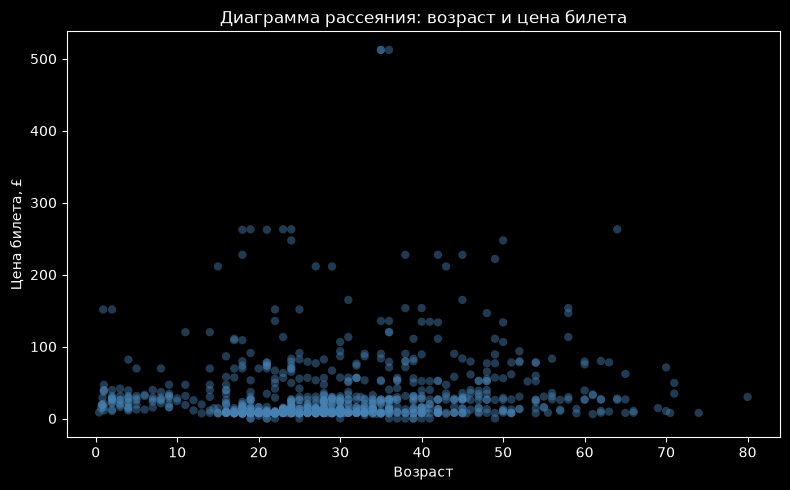

Корреляция Пирсона: 0.112
Связь слабая. Дорогие билеты встречаются в разном возрасте, а основная масса точек лежит у невысоких цен по всей шкале возраста.
Возраст практически не определяет цену билета: заметны горизонтальные полосы одинаковых тарифов и несколько очень дорогих билетов вне зависимости от возраста.


In [26]:
plt.figure(figsize=(8, 5))
plt.scatter(df['Age'], df['Fare'], alpha=0.45, color='steelblue', edgecolors='none')
plt.xlabel('Возраст')
plt.ylabel('Цена билета, £')
plt.title('Диаграмма рассеяния: возраст и цена билета')
plt.tight_layout()
plt.show()

correlation = df['Age'].corr(df['Fare'])
print(f'Корреляция Пирсона: {correlation:.3f}')
print('Связь слабая. Дорогие билеты встречаются в разном возрасте, а основная масса точек лежит у невысоких цен по всей шкале возраста.')
print('Возраст практически не определяет цену билета: заметны горизонтальные полосы одинаковых тарифов и несколько очень дорогих билетов вне зависимости от возраста.')

8. Отнормируйте значения признаков "Возраст" и "Цена билета". Выведите на экран полученный датасет.

In [27]:
for column in ['Age', 'Fare']:
    min_value = df[column].min()
    max_value = df[column].max()
    df[column] = (df[column] - min_value) / (max_value - min_value)

df

,Survived,Pclass,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare,Sex_female,Sex_male
0,0,3,0.271174,1,0,0.014151,0,1
1,1,1,0.472229,1,0,0.139136,1,0
2,1,3,0.321438,0,0,0.015469,1,0
3,1,1,0.434531,1,0,0.103644,1,0
4,0,3,0.434531,0,0,0.015713,0,1
...,...,...,...,...,...,...,...,...
882,0,2,0.334004,0,0,0.025374,0,1
883,1,1,0.233476,0,0,0.058556,1,0
884,0,3,0.082684,1,2,0.045771,1,0
885,1,1,0.321438,0,0,0.058556,0,1


9. Постройте гистограммы распределения пассажиров по полу и по возрасту для каждого класса. Расположите гистограммы одна под другой. Оси абсцисс должны быть однаковыми.

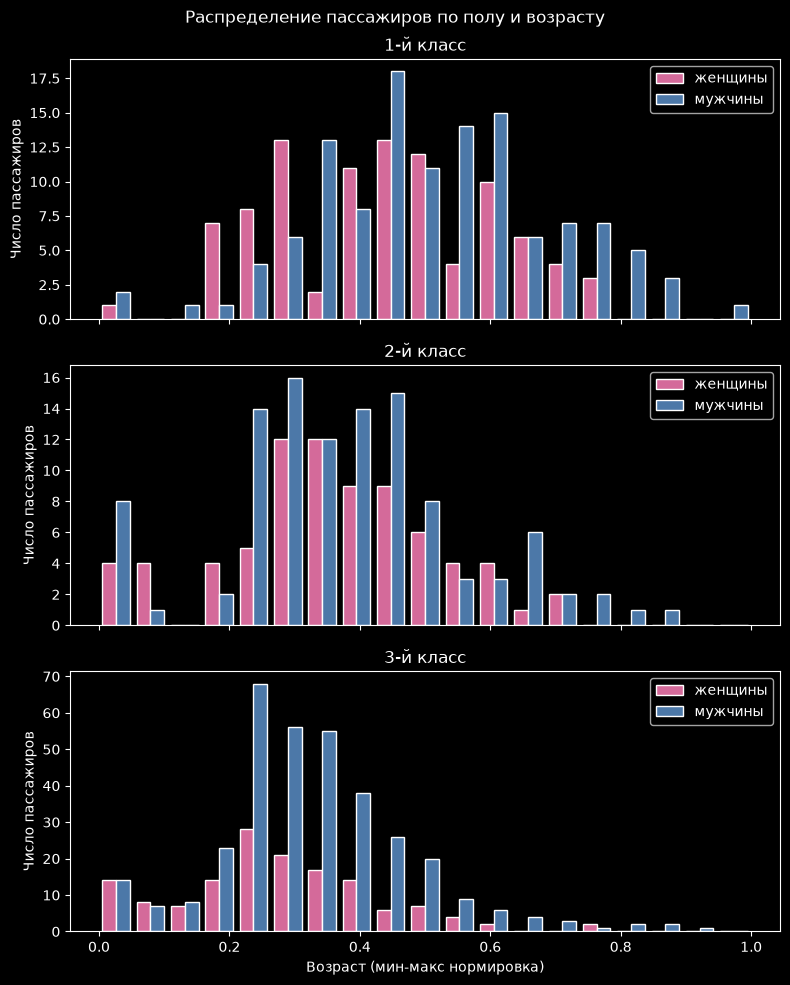

In [28]:
age_bins = np.linspace(df['Age'].min(), df['Age'].max(), 20)

fig, axes = plt.subplots(3, 1, figsize=(8, 10), sharex=True)
for ax, pclass in zip(axes, (1, 2, 3)):
    class_df = df[df['Pclass'] == pclass]
    ax.hist(
        [
            class_df.loc[class_df['Sex_female'] == 1, 'Age'],
            class_df.loc[class_df['Sex_male'] == 1, 'Age'],
        ],
        bins=age_bins,
        label=['женщины', 'мужчины'],
        color=['#d46a9a', '#4c78a8'],
        edgecolor='white',
    )
    ax.set_title(f'{pclass}-й класс')
    ax.set_ylabel('Число пассажиров')
    ax.legend()

axes[-1].set_xlabel('Возраст (мин-макс нормировка)')
fig.suptitle('Распределение пассажиров по полу и возрасту')
fig.tight_layout()
plt.show()

10. Сделайте выводы по работе.

В датасете 887 пассажиров и 8 признаков, пропущенных значений нет. Вторым классом вместе с родителями или детьми путешествовали 50 человек.

Цена билета распределена неравномерно: большинство билетов дешёвые, а справа есть длинный хвост и явные выбросы. Возраст почти не связан с ценой билета (корреляция около 0.11).

Утверждение «мужчинам выжить проще» не верно. Выжили около 74% женщин и около 19% мужчин. По гистограммам в третьем классе заметно больше мужчин и больше молодых пассажиров, а в первом классе возраст в среднем выше.

Для дальнейшего анализа столбец с именем удалён, пол закодирован one-hot-признаками `Sex_female` и `Sex_male`, а возраст и цена билета приведены к диапазону [0, 1] мин-макс нормировкой.